# Training: Echo State Network mit PyTorch

---

## Was ist Reservoir Computing?

Ein **Echo State Network (ESN)** ist eine spezielle Art von neuronalem Netz für **Zeitreihen**.

Die Grundidee:
- Ein grosses, **zufälliges und fixes** Reservoir-Netzwerk verarbeitet den Input
- Nur die **Ausgabeschicht** (`nn.Linear`) wird trainiert

```
Eingabe (y_t)  →  Reservoir (zufällig, fix)  →  nn.Linear  →  Ausgabe (y_t+1)
                       ↑↓ (rekurrent)
```

### Aufbau
1. Imports & Daten laden
2. ESN als `nn.Module` implementieren
3. Training mit MSE Loss und Adam Optimizer
4. Auswertung auf Testdaten

## 1. Imports und Daten laden

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Gerät festlegen: GPU wenn vorhanden, sonst CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Verwendetes Gerät: {device}")

# Reproduzierbarkeit
torch.manual_seed(42)
np.random.seed(42)

# Daten aus Notebook 01 laden
train_data = np.load('data/oscillations.npy',      allow_pickle=True)
test_data  = np.load('data/oscillations_test.npy', allow_pickle=True)

print(f"Trainingsdaten: {len(train_data)} Schwingungen")
print(f"Testdaten:      {len(test_data)} Schwingungen")

Verwendetes Gerät: cpu
Trainingsdaten: 25 Schwingungen
Testdaten:      25 Schwingungen


## 2. Dataset und DataLoader

PyTorch nutzt `Dataset` und `DataLoader` um Daten effizient zu laden.

- **`Dataset`** — definiert *wie* ein einzelnes Sample aussieht
- **`DataLoader`** — gibt die Daten in Batches an das Netz weiter

Für die **One-Step-Ahead-Prediction** ist jedes Sample ein Paar:
- Eingabe: `y(t)` — der aktuelle Wert
- Ziel: `y(t+1)` — der nächste Wert

In [11]:
class OscillationDataset(Dataset):
    """
    Erstellt (input, target) Paare für One-Step-Ahead-Prediction.
    
    Aus einer Schwingung [y0, y1, y2, ..., yT] werden Paare:
    input  = [y0, y1, ..., yT-1]
    target = [y1, y2, ..., yT]
    """
    def __init__(self, oscillations):
        self.samples = []
        for osc in oscillations:
            y = torch.tensor(osc['y'], dtype=torch.float32)
            # Jeder Zeitschritt ist ein eigenes Sample
            for t in range(len(y) - 1):
                self.samples.append((y[t].unsqueeze(0), y[t+1].unsqueeze(0)))
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        return self.samples[idx]


# Dataset und DataLoader erstellen
train_dataset = OscillationDataset(train_data)
test_dataset  = OscillationDataset(test_data)

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=256, shuffle=False)

print(f"Trainings-Samples: {len(train_dataset)}")
print(f"Test-Samples:      {len(test_dataset)}")
print(f"Batches pro Epoche: {len(train_loader)}")

Trainings-Samples: 24975
Test-Samples:      24975
Batches pro Epoche: 98


## 3. Echo State Network als nn.Module

Das ESN wird als PyTorch-Modul implementiert:

| Komponente | PyTorch | Trainierbar? |
|---|---|---|
| `W_in` | `nn.Linear(1, N, bias=False)` | Nein (requires_grad=False) |
| `W` | `nn.Linear(N, N, bias=False)` | Nein (requires_grad=False) |
| `W_out` | `nn.Linear(N, 1)` | **Ja** |

**Forward-Pass:**
```
x(t) = tanh( W_in · u(t) + W · x(t-1) )
y(t+1) = W_out · x(t)
```

In [12]:
class EchoStateNetwork(nn.Module):
    """
    Echo State Network als PyTorch nn.Module.
    
    Das Reservoir (W_in, W) ist zufällig und fix.
    Nur die Ausgabeschicht (W_out) wird durch Backpropagation trainiert.
    """

    def __init__(self, n_reservoir=300, spectral_radius=0.9, sparsity=0.1):
        super().__init__()
        self.n_reservoir = n_reservoir

        # --- Eingabe-Gewichte W_in (fix) ---
        W_in = torch.empty(n_reservoir, 1).uniform_(-1, 1)
        # register_buffer: Teil des Modells, aber KEIN Parameter → wird nicht trainiert
        self.register_buffer('W_in', W_in)

        # --- Reservoir-Gewichte W (fix, sparse) ---
        W = torch.empty(n_reservoir, n_reservoir).uniform_(-1, 1)
        # Sparsity: zufällig viele Gewichte auf 0 setzen
        mask = torch.rand_like(W) > sparsity
        W[mask] = 0.0
        # Spectral Radius skalieren (grösster Eigenwert = spectral_radius)
        eigenvalues = torch.linalg.eigvals(W)
        current_radius = eigenvalues.abs().max()
        W = W * (spectral_radius / current_radius.item())
        self.register_buffer('W', W)

        # --- Ausgabeschicht W_out (trainierbar) ---
        # nn.Linear macht: output = W_out * x + bias
        self.W_out = nn.Linear(n_reservoir, 1)

        print(f"ESN erstellt: {n_reservoir} Reservoir-Neuronen")
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        total     = sum(p.numel() for p in self.parameters()) + sum(b.numel() for b in self.buffers())
        print(f"Trainierbare Parameter: {trainable} von {total} gesamt")

    def forward(self, u, x=None):
        """
        Einen Zeitschritt vorwärts.
        
        u : Eingabe-Tensor der Form (batch, 1)
        x : aktueller Reservoir-Zustand (batch, n_reservoir), None = Nullvektor
        
        Gibt zurück: (Vorhersage, neuer Zustand)
        """
        batch = u.shape[0]
        if x is None:
            x = torch.zeros(batch, self.n_reservoir, device=u.device)

        # Reservoir-Update: x = tanh(W_in * u + W * x)
        # u: (batch, 1) → W_in: (N, 1) → W_in.T: (1, N) → matmul: (batch, N)
        x = torch.tanh(
            u @ self.W_in.T +   # Eingabe-Anteil
            x @ self.W.T        # rekurrenter Anteil
        )

        # Ausgabe: y = W_out * x
        y = self.W_out(x)  # (batch, 1)
        return y, x


# Modell erstellen und auf Gerät verschieben
model = EchoStateNetwork(
    n_reservoir=300,
    spectral_radius=0.95,
    sparsity=0.1
).to(device)

ESN erstellt: 300 Reservoir-Neuronen
Trainierbare Parameter: 301 von 90601 gesamt


## 4. Training

Wir trainieren die Ausgabeschicht mit:
- **Loss:** `nn.MSELoss` — mittlerer quadratischer Fehler zwischen Vorhersage und echtem nächsten Wert
- **Optimizer:** `Adam` — adaptiver Lernraten-Algorithmus, robust und weit verbreitet

Da jedes Sample unabhängig ist (einzelne Zeitschritte), können wir normal mit Batches trainieren.
Der Reservoir-Zustand `x` wird **pro Batch zurückgesetzt** — das vereinfacht das Training erheblich.

Epoche  1/20 — Loss: 0.015437
Epoche  2/20 — Loss: 0.012411
Epoche  3/20 — Loss: 0.011677
Epoche  4/20 — Loss: 0.011437
Epoche  5/20 — Loss: 0.011514
Epoche  6/20 — Loss: 0.011415
Epoche  7/20 — Loss: 0.011408
Epoche  8/20 — Loss: 0.011488
Epoche  9/20 — Loss: 0.011552
Epoche 10/20 — Loss: 0.011538
Epoche 11/20 — Loss: 0.011519
Epoche 12/20 — Loss: 0.011413
Epoche 13/20 — Loss: 0.011522
Epoche 14/20 — Loss: 0.011390
Epoche 15/20 — Loss: 0.011392
Epoche 16/20 — Loss: 0.011446
Epoche 17/20 — Loss: 0.011404
Epoche 18/20 — Loss: 0.011410
Epoche 19/20 — Loss: 0.011387
Epoche 20/20 — Loss: 0.011403


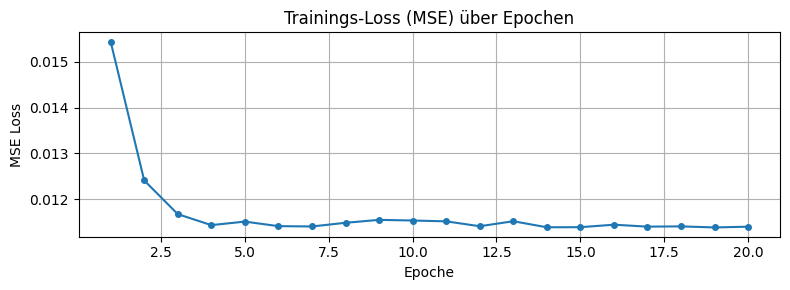

In [13]:
# Loss-Funktion und Optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

N_EPOCHS = 20
train_losses = []

model.train()
for epoch in range(N_EPOCHS):
    epoch_loss = 0.0

    for u_batch, target_batch in train_loader:
        u_batch      = u_batch.to(device)       # (batch, 1)
        target_batch = target_batch.to(device)  # (batch, 1)

        # Vorwärtspass: Reservoir-Zustand pro Batch neu starten
        pred, _ = model(u_batch)

        # Loss berechnen
        loss = criterion(pred, target_batch)

        # Rückwärtspass (Backpropagation) — nur W_out wird aktualisiert
        optimizer.zero_grad()  # Gradienten zurücksetzen
        loss.backward()        # Gradienten berechnen
        optimizer.step()       # Gewichte aktualisieren

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_loss)
    print(f"Epoche {epoch+1:2d}/{N_EPOCHS} — Loss: {avg_loss:.6f}")

# Loss-Verlauf plotten
plt.figure(figsize=(8, 3))
plt.plot(range(1, N_EPOCHS+1), train_losses, marker='o', markersize=4)
plt.title('Trainings-Loss (MSE) über Epochen')
plt.xlabel('Epoche')
plt.ylabel('MSE Loss')
plt.grid(True)
plt.tight_layout()
plt.show()

## 5. Auswertung auf Testdaten

Wir lassen das Modell jede Testschwingung **sequenziell** durchlaufen:
Der Reservoir-Zustand `x` wird von Schritt zu Schritt weitergegeben — so nutzt das ESN sein Gedächtnis.

Als Fehlermetrik verwenden wir den **RMSE**:
$$\text{RMSE} = \sqrt{\frac{1}{N}\sum_{t=1}^{N}(\hat{y}_t - y_t)^2}$$

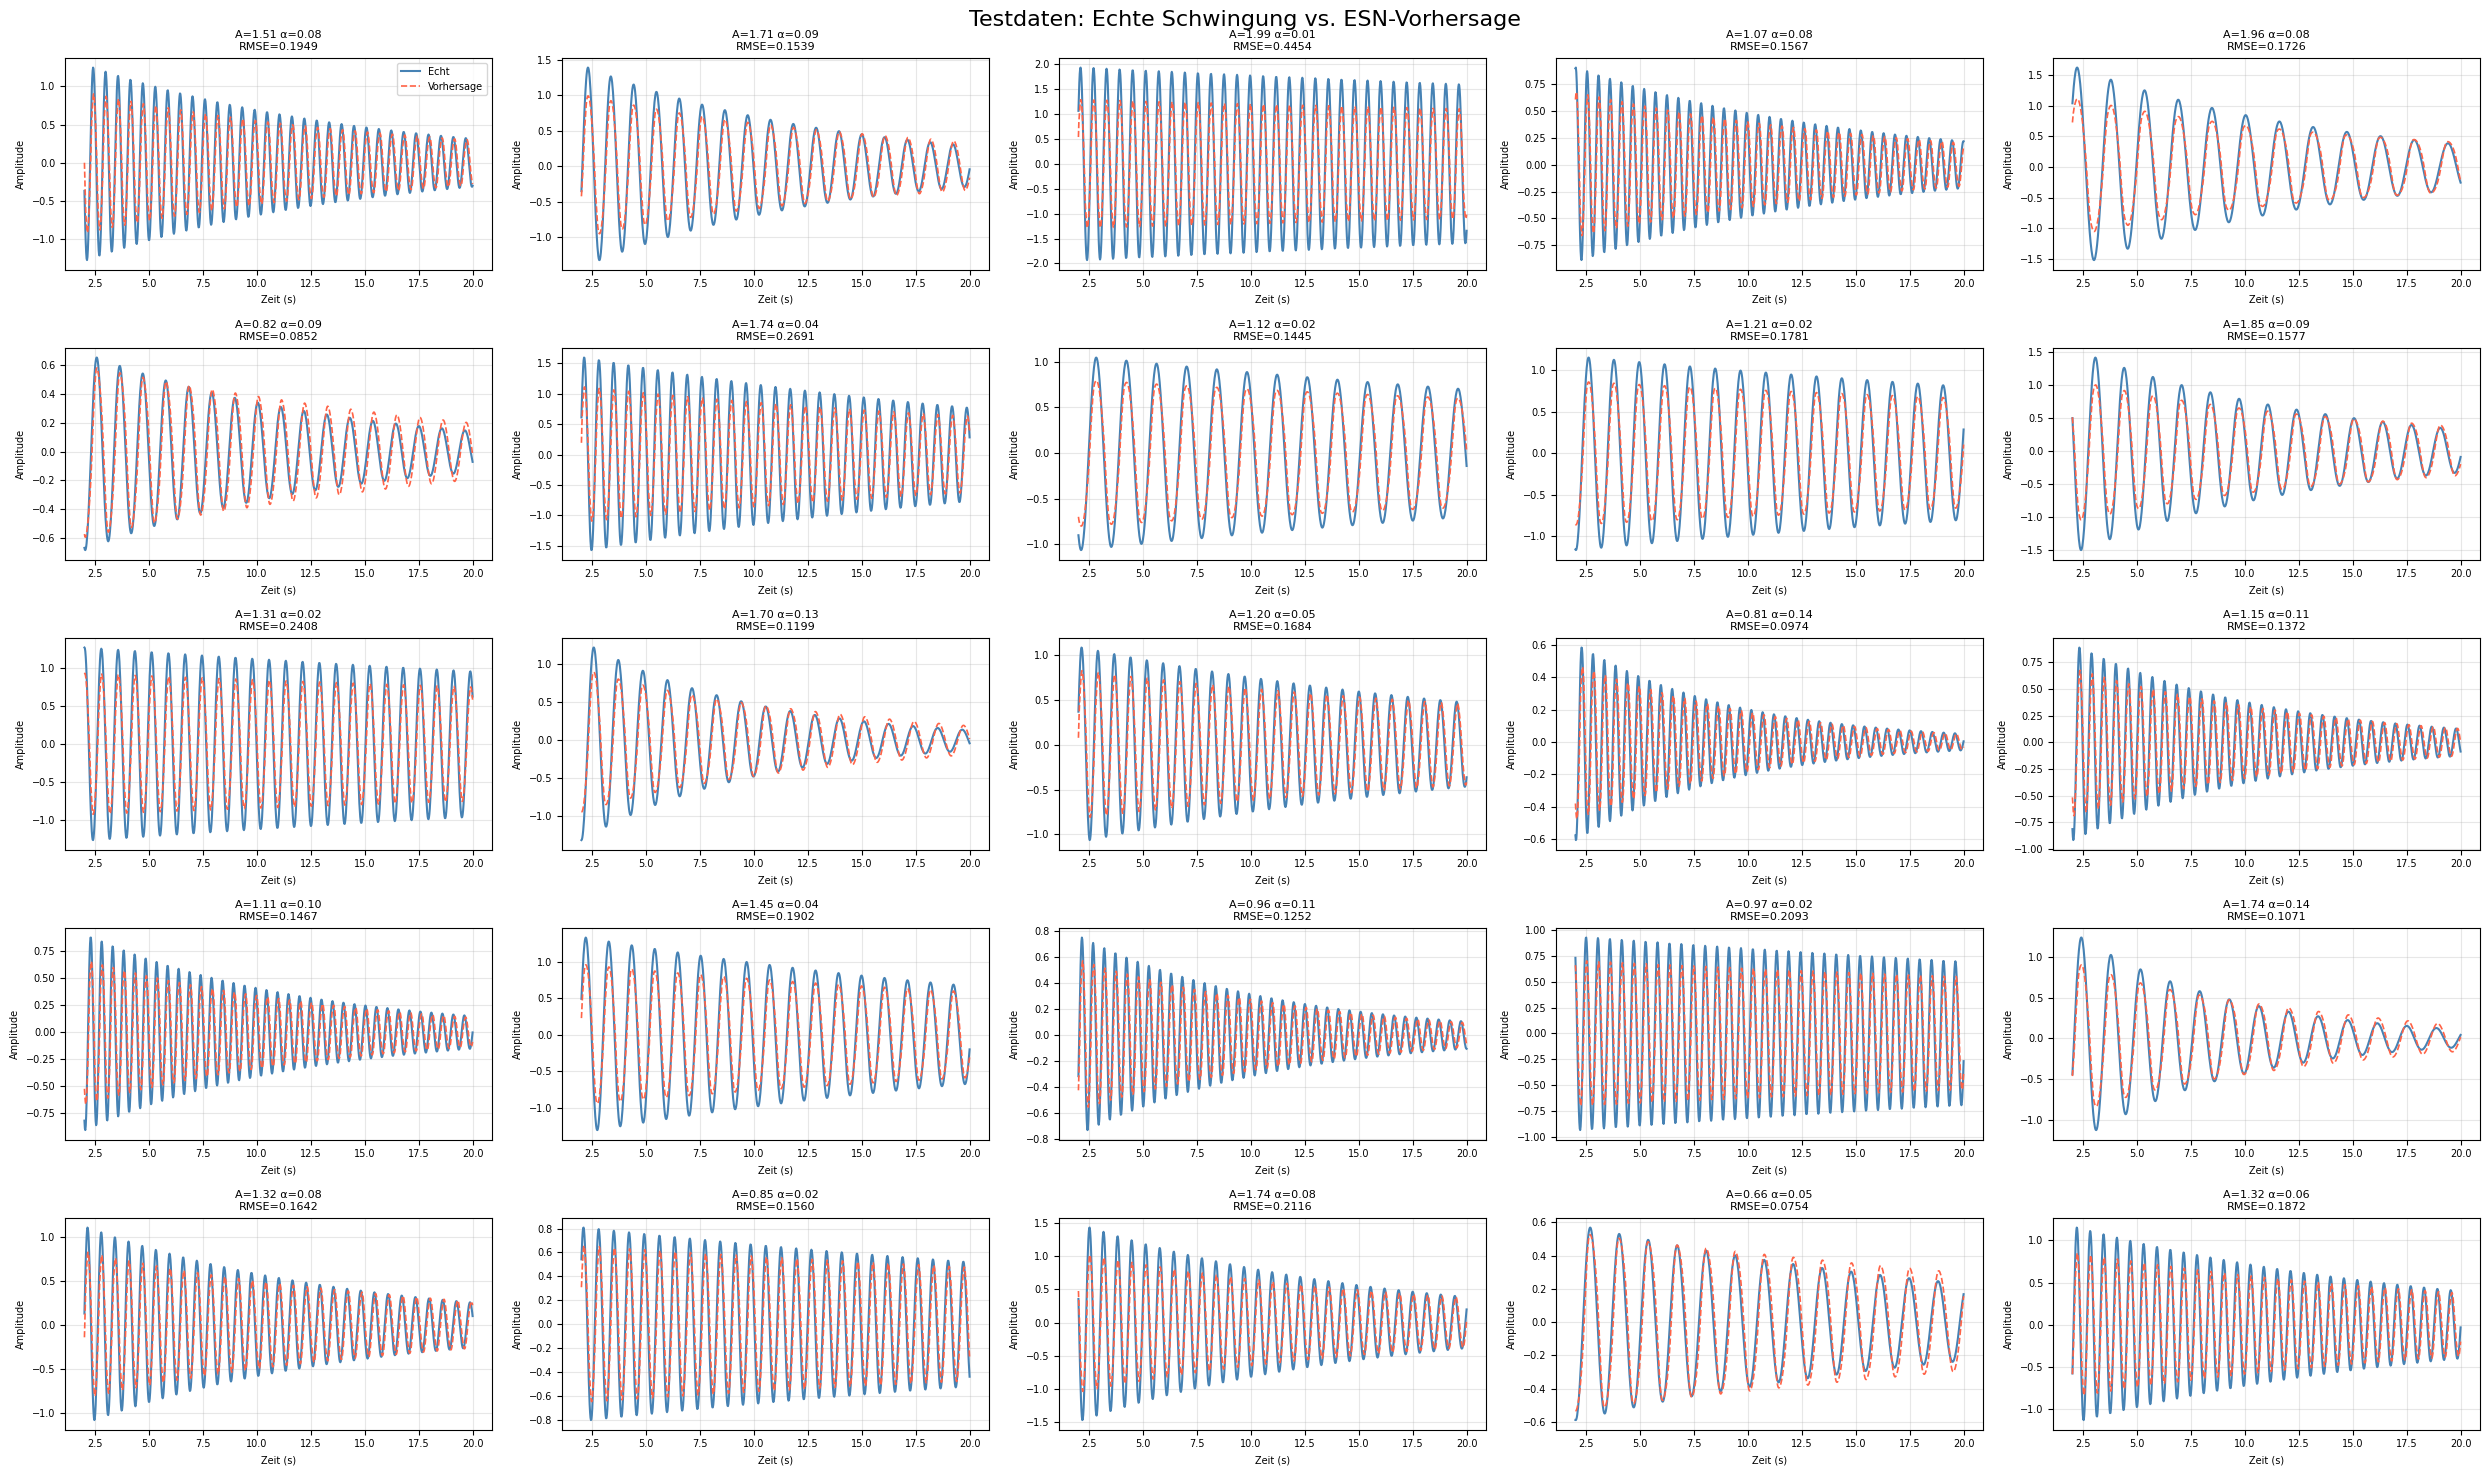


Durchschnittlicher RMSE: 0.17179
Bester RMSE:             0.07544
Schlechtester RMSE:      0.44536


In [14]:
WARMUP = 100  # erste 100 Schritte ignorieren (Reservoir einschwingen lassen)

model.eval()
rmse_list = []

fig, axes = plt.subplots(5, 5, figsize=(25, 15))
fig.suptitle("Testdaten: Echte Schwingung vs. ESN-Vorhersage", fontsize=16)
axes = axes.flatten()

with torch.no_grad():  # kein Gradient nötig bei Auswertung → spart Speicher
    for i, osc in enumerate(test_data):
        y_np = osc['y']
        t_np = osc['t']
        y_tensor = torch.tensor(y_np, dtype=torch.float32, device=device)

        # Sequenziell durchlaufen — Zustand x weitergeben
        x = None
        preds = []
        for t in range(len(y_tensor) - 1):
            u = y_tensor[t].view(1, 1)  # (1, 1)
            pred, x = model(u, x)
            preds.append(pred.item())

        preds = np.array(preds)

        # Nach Warmup auswerten
        y_ref  = y_np[WARMUP+1:]
        y_pred = preds[WARMUP:]
        t_plot = t_np[WARMUP+1:]

        rmse = np.sqrt(np.mean((y_pred - y_ref) ** 2))
        rmse_list.append(rmse)

        # Plot
        axes[i].plot(t_plot, y_ref,  label='Echt',       color='steelblue', linewidth=1.5)
        axes[i].plot(t_plot, y_pred, label='Vorhersage', color='tomato',    linewidth=1.2, linestyle='--')
        p = osc['params']
        axes[i].set_title(f"A={p['A']:.2f} α={p['α']:.2f}\nRMSE={rmse:.4f}", fontsize=8)
        axes[i].set_xlabel('Zeit (s)', fontsize=7)
        axes[i].set_ylabel('Amplitude', fontsize=7)
        axes[i].tick_params(labelsize=7)
        axes[i].grid(True, alpha=0.3)
        if i == 0:
            axes[i].legend(fontsize=7)

plt.tight_layout()
plt.show()

print(f"\nDurchschnittlicher RMSE: {np.mean(rmse_list):.5f}")
print(f"Bester RMSE:             {np.min(rmse_list):.5f}")
print(f"Schlechtester RMSE:      {np.max(rmse_list):.5f}")

## 6. Zusammenfassung

### PyTorch-Konzepte die verwendet wurden

| Konzept | Wozu |
|---|---|
| `nn.Module` | Basisklasse für alle Netzwerke |
| `register_buffer` | Fixer Tensor im Modell (kein Gradient) |
| `nn.Linear` | Vollverbundene Schicht (trainierbar) |
| `nn.MSELoss` | Mittlerer quadratischer Fehler als Loss |
| `torch.optim.Adam` | Adaptiver Optimizer |
| `Dataset` / `DataLoader` | Effizientes Laden in Batches |
| `model.train()` / `model.eval()` | Trainings- vs. Auswertungsmodus |
| `torch.no_grad()` | Kein Gradient bei Auswertung |

### Hyperparameter zum Experimentieren

| Parameter | Effekt |
|---|---|
| `n_reservoir` | Grösser → mehr Kapazität |
| `spectral_radius` | Näher an 1 → längeres Gedächtnis |
| `N_EPOCHS` | Mehr → besseres Training (bis Overfitting) |
| `lr` in Adam | Kleiner → stabiler aber langsamer |